# Ensemble

Ensemble là gộp dự đoán của nhiều model. Gộp chỉ có lợi khi các model sai ở những chỗ khác nhau, để lỗi của model này được model kia bù. Nếu các model cùng sai một kiểu, ví dụ cùng dựa vào một dấu hiệu tình cờ trong ảnh, thì thêm bao nhiêu model cũng không giúp. Bài này học các cách gộp (bỏ phiếu, lấy trung bình, trung bình có trọng số, stacking) và cách chọn trọng số trên một tập rồi kiểm trên tập khác, để điểm báo cáo không bị đẹp giả.

> **Mục tiêu**
>
> - Tính các cách gộp: bỏ phiếu, trung bình xác suất, trung bình hạng, trung bình có trọng số.
> - Biết khi nào gộp có lợi.
> - Chọn trọng số trên một tập, kiểm trên tập khác.
> - Làm stacking bằng dự đoán out-of-fold.

## Gộp nhãn khác gộp xác suất

Hard voting chọn lớp được nhiều model dự đoán nhất. Soft voting lấy trung bình các xác suất từng lớp rồi chọn lớp có xác suất cao nhất. Hai cách có thể cho kết quả khác, vì hard voting bỏ mức tự tin. Ta lấy mẫu đầu tiên: ba xác suất lớp 1 là $0.51,0.51,0.01$. Hai model hơi nghiêng về lớp 1, một model nghiêng mạnh về lớp 0. Hard voting cho lớp 1, còn mean $1.03/3\approx0.343$ cho lớp 0.

In [ ]:
import numpy as np

# Mỗi hàng là một mẫu; mỗi cột là xác suất lớp 1 của một model.
probabilities = np.array([
    [0.51, 0.51, 0.01],
    [0.90, 0.60, 0.60],
    [0.20, 0.80, 0.70],
    [0.80, 0.10, 0.10],
])
hard_labels = (probabilities >= 0.5).astype(int)
majority = (hard_labels.sum(axis=1) >= 2).astype(int)
mean_probability = probabilities.mean(axis=1)
soft_labels = (mean_probability >= 0.5).astype(int)
print("shape", probabilities.shape)
print("hard", majority.tolist())
print("mean probabilities", mean_probability.round(3).tolist())
print("soft", soft_labels.tolist())

shape (4, 3)
hard [1, 1, 1, 0]
mean probabilities [0.343, 0.7, 0.567, 0.333]
soft [0, 1, 1, 0]


Đọc hàng đầu để thấy hai đáp án khác nhau. Soft voting không luôn đúng hơn: một model tự tin sai có thể kéo mean sang lớp sai. Xác suất được hiệu chỉnh (calibrated) giúp mức tự tin có ý nghĩa; một model cho 0.9 cần đúng gần 90% trên các trường hợp tương tự để cách đọc ấy hợp lý. Tài liệu [VotingClassifier](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.VotingClassifier.html) phân biệt hai cơ chế và khuyến nghị soft voting cho các bộ phân loại có xác suất được hiệu chỉnh tốt.

Với $K$ model và trọng số không âm $w_k$ có tổng 1, xác suất gộp là

$$p(c\mid x)=\sum_{k=1}^{K}w_k p_k(c\mid x).$$

$c$ chỉ lớp, $x$ chỉ một mẫu. Với bài hồi quy, thay xác suất bằng giá trị dự đoán là trung bình dự đoán. Không gộp ID hay chỉ số lớp như một số thực: trung bình nhãn `cat=0`, `dog=1`, `bird=2` thành 1 không có ý nghĩa “ở giữa mèo và chim”. Nếu model xuất logits, mean logits rồi softmax khác mean probabilities; chọn cách nào phải được kiểm đúng metric. Hard voting với số model chẵn có thể hòa phiếu; khi hòa, `VotingClassifier` và `np.argmax(np.bincount(...))` đều chọn lớp có chỉ số nhỏ hơn, một quy tắc ngầm mà người viết không chủ ý đặt. Số model lẻ tránh hòa với hai lớp; với nhiều lớp, ba model trả ba nhãn khác nhau vẫn hòa.



**Hỏi nhanh.** Hai model cho xác suất lớp 1 là 0.2 và 0.8, với trọng số lần lượt là 0.75 và 0.25. Xác suất gộp bằng bao nhiêu?

- A. 0.5
- B. 0.35
- C. 0.65
- D. 1.0

<details><summary>Đáp án</summary>

B. 0.35

$0.75\cdot 0.2 + 0.25\cdot 0.8 = 0.35$. Trọng số đi theo đúng model, không theo giá trị lớn hay nhỏ. 0.5 là trung bình đều, bỏ qua trọng số. 0.65 là đảo trọng số giữa hai model. 1.0 là cộng hai xác suất mà không nhân trọng số.

</details>

**Hỏi nhanh.** Ba model nhị phân cho logit $+5$, $-2$, $-2$ ở cùng một mẫu, và mẫu thuộc lớp 1 nếu xác suất từ 0.5 trở lên. Lấy trung bình logit rồi qua sigmoid, và lấy trung bình các xác suất sigmoid, lần lượt cho lớp nào?

- A. Trung bình logit cho lớp 0, trung bình xác suất cho lớp 0
- B. Trung bình logit cho lớp 0, trung bình xác suất cho lớp 1
- C. Trung bình logit cho lớp 1, trung bình xác suất cho lớp 0
- D. Trung bình logit cho lớp 1, trung bình xác suất cho lớp 1

<details><summary>Đáp án</summary>

C. Trung bình logit cho lớp 1, trung bình xác suất cho lớp 0

Trung bình logit là $1/3$, qua sigmoid khoảng 0.583, nên ra lớp 1. Sigmoid của từng model là 0.993, 0.119 và 0.119, trung bình khoảng 0.411, nên ra lớp 0. Logit $+5$ kéo mạnh vì thang logit không bị chặn, còn sigmoid ép nó về tối đa là 1. Hai cách gộp này khác nhau thật, chứ không phải hai cách làm tròn của cùng một phép tính.

</details>



## Khi metric chỉ xét thứ tự: trung bình hạng

AUC và các metric xếp hạng chỉ dùng thứ tự điểm giữa các mẫu, không dùng độ lớn. Hai model thường cho điểm ở hai thang khác nhau: một model nén mọi điểm quanh 0.5, model kia trải từ 0.05 đến 0.95. Trung bình điểm thô để model thang rộng lấn át, dù hai model có giá trị như nhau. Trung bình hạng (rank averaging) đổi điểm của mỗi model thành hạng của mẫu trong tập, rồi lấy trung bình các hạng. Ví dụ dựng sẵn dưới đây có sáu mẫu, ba âm và ba dương.

In [ ]:
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

y_small = np.array([0, 0, 0, 1, 1, 1])
score_a = np.array([0.47, 0.48, 0.50, 0.49, 0.52, 0.53])   # thang hẹp quanh 0.5
score_b = np.array([0.20, 0.70, 0.05, 0.85, 0.40, 0.95])   # thang rộng
mean_score = (score_a + score_b) / 2
rank_score = (rankdata(score_a) + rankdata(score_b)) / 2
for name, score in [("A", score_a), ("B", score_b),
                    ("mean", mean_score), ("rank mean", rank_score)]:
    print(name, "AUC", f"{roc_auc_score(y_small, score):.3f}")
print("rank scores", rank_score.tolist())

A AUC 0.889
B AUC 0.889
mean AUC 0.889
rank mean AUC 1.000
rank scores [1.5, 3.0, 2.5, 4.0, 4.0, 6.0]


Mỗi model xếp đúng 8 trên 9 cặp (dương, âm), nên AUC là 0.889. A sai ở một cặp (mẫu dương 0.49 thấp hơn mẫu âm 0.50), B sai ở một cặp khác (mẫu âm 0.70 cao hơn mẫu dương 0.40). Trung bình điểm thô sửa được lỗi của A nhờ B, nhưng giữ lại lỗi của B: khoảng cách điểm của B ở cặp ấy là 0.30, của A chỉ 0.04, nên B lấn át. Trung bình hạng cho mỗi model đóng góp theo thứ tự thay vì theo độ rộng thang, và cả hai lỗi đều bị model kia ghi đè: AUC lên 1.000.



Hạng chỉ có nghĩa trong một tập dự đoán đầy đủ, vì hạng của một mẫu phụ thuộc mọi mẫu khác. Test chia thành nhiều file phải được gộp trước khi xếp hạng. Hạng cũng không phải xác suất: log loss, F1 theo ngưỡng và mọi metric cần độ lớn không tính được trên hạng.

**Hỏi nhanh.** Test gồm hai file, mỗi file 5000 mẫu, và metric là AUC trên cả 10 000 mẫu. Hai model đã dự đoán xong. Lấy trung bình hạng thế nào cho đúng?

- A. Gộp hai file, xếp hạng chung, rồi tách lại theo ID
- B. Xếp hạng riêng từng file, rồi nối hai bảng hạng lại
- C. Xếp hạng file đầu, giữ điểm thô cho file sau
- D. Với mỗi mẫu, xếp hạng hai model rồi lấy trung bình

<details><summary>Đáp án</summary>

A. Gộp hai file, xếp hạng chung, rồi tách lại theo ID

Hạng là vị trí của mẫu trong tập được chấm, nên phải tính trên toàn bộ 10 000 mẫu. Xếp hạng từng file riêng thì có hai thang từ 1 đến 5000 chồng lên nhau, và hạng của một mẫu ở file này không so được với hạng ở file kia. Giữ điểm thô ở file sau là trộn hai thang đo trong cùng một cột. Xếp hạng hai model theo từng mẫu là lấy sai trục: hạng cần tính qua các mẫu, trong từng model.

</details>

## Nhiều model giảm phần lỗi nào?

Hãy tưởng tượng ba người cùng đo một chiều dài. Nếu sai số đo độc lập, lấy trung bình giảm dao động. Nếu cả ba dùng một thước bị lệch thêm 2 cm, lấy trung bình vẫn lệch 2 cm. Ensemble cũng vậy: khác seed có thể giảm dao động huấn luyện, nhưng cùng dùng một nhãn sai, một split rò rỉ hoặc một đường tắt thì lỗi chung còn nguyên.

Một công thức nhỏ cho trực giác. Giả sử các sai số $\epsilon_k$ đều có trung bình 0, phương sai $\sigma^2$ và mọi cặp có cùng tương quan $\rho$. Phương sai của trung bình là

$$\operatorname{Var}(\bar\epsilon)=\frac{\sigma^2}{K}\bigl(1+(K-1)\rho\bigr).$$

Có $K$ hạng phương sai trên đường chéo và $K(K-1)$ hạng hiệp phương sai, mỗi hạng bằng $\rho\sigma^2$; chia tổng cho $K^2$ cho công thức. Nếu $\rho=0$, phương sai giảm còn $\sigma^2/K$. Nếu $\rho=1$, nó vẫn là $\sigma^2$. Nếu $\rho>0$, tăng model mãi còn giới hạn $\rho\sigma^2$. Đây là mô hình sai số đơn giản, không phải định luật dự báo accuracy của mọi ensemble.

In [ ]:
for correlation in [0.0, 0.5, 1.0]:
    k = 4
    variance_ratio = (1 + (k - 1) * correlation) / k
    print("rho", correlation, "variance ratio", f"{variance_ratio:.3f}")

rho 0.0 variance ratio 0.250
rho 0.5 variance ratio 0.625
rho 1.0 variance ratio 1.000


Bốn model độc lập cho tỉ lệ 0.25; tương quan 0.5 cho 0.625; giống hệt nhau cho 1.0. Đó là lý do ta xem **mẫu sai**, không chỉ xem metric mỗi model. Model thứ hai có thể hơi yếu hơn tổng thể nhưng sửa đúng một nhóm model thứ nhất thường sai. Nó cũng có thể bất đồng vì quá yếu; bất đồng tự nó chưa chứng minh ích lợi.



**Hỏi nhanh.** Mười bản cùng kiến trúc, cùng dữ liệu, chỉ khác seed, và sai số của mọi cặp có tương quan $\rho = 0.9$. Theo mô hình của bài, phương sai của sai số trung bình bằng bao nhiêu so với một bản?

- A. $0.10\sigma^2$
- B. $0.90\sigma^2$
- C. $1.00\sigma^2$
- D. $0.91\sigma^2$

<details><summary>Đáp án</summary>

D. $0.91\sigma^2$

$\frac{1}{10}(1 + 9\cdot 0.9) = 0.91$. $0.10\sigma^2$ chỉ đúng khi sai số độc lập, tức $\rho = 0$. $0.90\sigma^2$ là giới hạn khi số bản tiến tới vô hạn. Với $K = 10$ còn thêm phần $(1 - \rho)\sigma^2/K = 0.01\sigma^2$. $1.00\sigma^2$ chỉ xảy ra khi $\rho = 1$. Mười bản chỉ giảm được khoảng 9% phương sai, chứ không phải 90%.

</details>

Bỏ phiếu cũng theo logic ấy. Giả sử $K$ model nhị phân, mỗi model đúng với xác suất $p$ trên mỗi mẫu và sai độc lập nhau; đa số đúng khi có quá nửa số model đúng, xác suất ấy là một tổng nhị thức. Hàm dưới đây tính nó, rồi thử một phần số mẫu mà cả ba model luôn cùng đúng hoặc cùng sai (lỗi trùng hoàn toàn), phần còn lại độc lập.

In [ ]:
from math import comb

def majority_accuracy(p, k):
    """k model độc lập, mỗi model đúng với xác suất p; đa số đúng khi hơn nửa số model đúng."""
    return sum(comb(k, j) * p**j * (1 - p)**(k - j) for j in range(k // 2 + 1, k + 1))

print("p=0.7", "3 models", f"{majority_accuracy(0.7, 3):.3f}",
      "15 models", f"{majority_accuracy(0.7, 15):.3f}")
for shared in [0.0, 0.5, 1.0]:
    vote = shared * 0.7 + (1 - shared) * majority_accuracy(0.7, 3)
    print("shared", shared, "vote of 3", f"{vote:.3f}")

p=0.7 3 models 0.784 15 models 0.950
shared 0.0 vote of 3 0.784
shared 0.5 vote of 3 0.742
shared 1.0 vote of 3 0.700


Ba model độc lập, mỗi model đúng 70%, cho 0.784; mười lăm model cho 0.950. Khi một nửa số mẫu có lỗi trùng hoàn toàn (`shared=0.5`), ba model chỉ còn 0.742; khi mọi lỗi trùng (`shared=1.0`), bỏ phiếu bằng đúng một model, 0.700. Điều kiện $p>0.5$ cũng bắt buộc: khi mỗi model đúng ít hơn nửa số mẫu, thêm model làm bỏ phiếu tệ hơn nữa. Boosting đặt điều kiện tương tự: weak learner phải hơn đoán ngẫu nhiên.



**Hỏi nhanh.** Ba model đều đúng 70%. Trên một nửa số mẫu, cả ba luôn cùng đúng hoặc cùng sai. Trên nửa còn lại, ba model sai độc lập với nhau. Bỏ phiếu đa số cho accuracy gần mức nào nhất?

- A. 0.700
- B. 0.742
- C. 0.784
- D. 0.850

<details><summary>Đáp án</summary>

B. 0.742

Nửa trùng lỗi cho 0.700, nửa độc lập cho 0.784, nên trung bình hai nửa là $0.5\cdot 0.700 + 0.5\cdot 0.784 = 0.742$. 0.784 chỉ đúng khi lỗi độc lập trên mọi mẫu, và 0.700 chỉ đúng khi lỗi trùng nhau trên mọi mẫu. Không có cách nào ra 0.850 từ ba model đúng 70% mà không thêm thông tin mới.

</details>

## Chuẩn bị ba phần dữ liệu có vai trò riêng

Dữ liệu là hai hình bán nguyệt nhiễu từ `make_moons`, sinh tại chỗ. Mỗi mẫu có hai đặc trưng, nhãn 0 hoặc 1. Ta dành 360 mẫu để fit model, 120 mẫu `tune` để chọn trọng số, 120 mẫu `audit` để kiểm phương án đã khóa. Tên `audit` chỉ gọi tập kiểm giữ riêng trong notebook.

In [ ]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import log_loss, accuracy_score

X, y = make_moons(n_samples=600, noise=0.28, random_state=84)
X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, test_size=0.4, random_state=1, stratify=y)
X_tune, X_audit, y_tune, y_audit = train_test_split(
    X_hold, y_hold, test_size=0.5, random_state=2, stratify=y_hold)
models = {
    "linear": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    "forest": RandomForestClassifier(n_estimators=40, max_depth=5,
                                     min_samples_leaf=3, random_state=0, n_jobs=1),
    "knn": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}
tune_probs = []
audit_probs = []
for name, model in models.items():
    model.fit(X_train, y_train)
    assert np.array_equal(model.classes_, [0, 1])
    p_tune = model.predict_proba(X_tune)
    p_audit = model.predict_proba(X_audit)
    tune_probs.append(p_tune)
    audit_probs.append(p_audit)
    print(name, "tune logloss", f"{log_loss(y_tune, p_tune):.4f}")
tune_probs = np.stack(tune_probs)
audit_probs = np.stack(audit_probs)
print("train/tune/audit", len(y_train), len(y_tune), len(y_audit))
print("probability shape", tune_probs.shape)

linear tune logloss 0.3229
forest tune logloss 0.2240
knn tune logloss 0.4201
train/tune/audit 360 120 120
probability shape (3, 120, 2)


Shape `(3,120,2)` có thứ tự **model, mẫu, lớp**. `predict_proba` cột đầu là lớp 0, cột sau là lớp 1 vì đã kiểm `classes_`. Khi dùng pandas ghép dự đoán, ta giữ cùng thứ tự ID; một tensor cùng shape nhưng hàng lệch vẫn cho một mean vô nghĩa. Fit scaler chỉ trên train nhờ `Pipeline`; tập audit chưa tham gia chọn trọng số.



**Hỏi nhanh.** `P.shape == (3, 120, 2)`. Muốn lấy trung bình qua các model mà vẫn giữ mẫu và lớp thì dùng gì?

- A. `P.mean(axis=0)`, cho shape `(120, 2)`
- B. `P.mean(axis=1)`, cho shape `(3, 2)`
- C. `P.mean(axis=2)`, cho shape `(3, 120)`
- D. `P.mean()`, cho một số

<details><summary>Đáp án</summary>

A. `P.mean(axis=0)`, cho shape `(120, 2)`

Trục 0 là model, nên gộp trục đó giữ đúng một phân phối lớp cho mỗi mẫu. Trục 1 là mẫu và trục 2 là lớp, nên gộp chúng là trộn các mẫu hoặc các lớp với nhau. `P.mean()` không có đối số thì chỉ trả về một số.

</details>

## Chọn trọng số bằng một tập, đánh giá bằng tập khác

Ta thử một lưới nhỏ: trọng số là bội của 0.25, không âm và tổng 1. Viết trọng số là $(a,b,c)/4$ với $a+b+c=4$ nguyên không âm thì có $\binom{6}{2}=15$ bộ. Đây là một không gian giả thuyết đã định trước, đủ nhỏ để đọc. Với $K$ model và lưới bước $1/g$, số bộ là $\binom{g+K-1}{K-1}$, tăng rất nhanh: bốn model và bước $1/20$ đã có 1771 bộ. Thử hàng nghìn trọng số trên 120 mẫu, ta có thể fit nhiễu của chính tune dù không fit thêm model nào.

In [ ]:
weight_grid = []
for first in range(5):
    for second in range(5 - first):
        third = 4 - first - second
        weight_grid.append(np.array([first, second, third]) / 4)

def combine(weights, probabilities):
    return np.tensordot(weights, probabilities, axes=(0, 0))

losses = [log_loss(y_tune, combine(w, tune_probs)) for w in weight_grid]
best_index = int(np.argmin(losses))
chosen_weights = weight_grid[best_index]
equal_weights = np.full(3, 1 / 3)
print("candidate weights", len(weight_grid))
print("chosen weights", chosen_weights.tolist())
print("chosen tune loss", f"{losses[best_index]:.4f}")
print("equal tune loss", f"{log_loss(y_tune, combine(equal_weights, tune_probs)):.4f}")

candidate weights 15
chosen weights [0.0, 0.25, 0.75]
chosen tune loss 0.1687
equal tune loss 0.2190


Ta khóa `chosen_weights` sau khối này. Trọng số 0 có nghĩa bỏ model đó, nên lưới đã gồm cả model đơn. Nếu equal weights không thắng model đơn, đó là một kết quả cần giữ, không phải lỗi phải che. Model mạnh trên tune có thể không mạnh ở một miền khác; kiểm lỗi theo nhóm từ bài 8.2 vẫn cần thiết.

Giờ mở tập audit **một lần cho phương án đã chọn**, đồng thời báo mốc model đơn và equal weights để hiểu hệ quả. Trong bài luyện thật, nếu dùng kết quả audit để sửa lại phương án, tập này đã trở thành validation; cần một tập đánh giá khác hoặc ghi đúng giới hạn phép đo.

In [ ]:
audit_ensemble = combine(chosen_weights, audit_probs)
for name, p in list(zip(models, audit_probs)) + [
    ("equal", combine(equal_weights, audit_probs)),
    ("chosen", audit_ensemble),
]:
    labels = np.argmax(p, axis=1)
    print(name, "audit logloss", f"{log_loss(y_audit, p):.4f}",
          "accuracy", f"{accuracy_score(y_audit, labels):.3f}")

linear audit logloss 0.3124 accuracy 0.842
forest audit logloss 0.2571 accuracy 0.892
knn audit logloss 0.4809 accuracy 0.925
equal audit logloss 0.2384 accuracy 0.908
chosen audit logloss 0.2113 accuracy 0.925




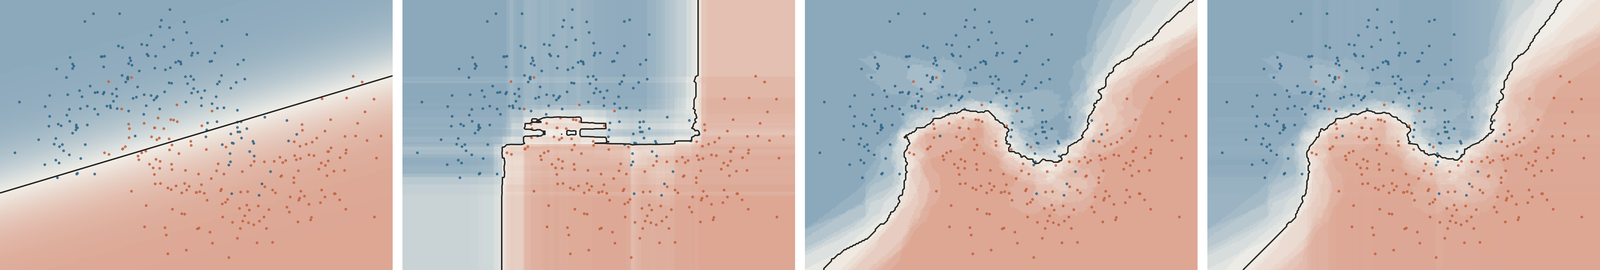

Đọc cả log loss và accuracy. Trong lần chạy này, kNN đơn và bản chọn đều đạt accuracy 0.925 trên audit, nhưng log loss giảm từ 0.4809 xuống 0.2113: một model có thể cho cùng nhãn mà xác suất bớt cực đoan. Lý do nằm ở chính kNN với 15 hàng xóm: khi cả 15 hàng xóm cùng nhãn, nó trả xác suất đúng 0 hoặc 1, và một lần tự tin sai bị log loss phạt gần như vô hạn. Ta đếm trên tune.

In [ ]:
knn_tune = tune_probs[2, :, 1]
extreme = (knn_tune == 0) | (knn_tune == 1)
wrong_extreme = extreme & ((knn_tune >= 0.5) != y_tune)
clipped = np.clip(tune_probs[2], 0.01, 0.99)
print("kNN extreme probabilities", int(extreme.sum()), "of", len(y_tune))
print("extreme and wrong", int(wrong_extreme.sum()))
print("kNN tune logloss raw", f"{log_loss(y_tune, tune_probs[2]):.4f}",
      "clipped", f"{log_loss(y_tune, clipped):.4f}")

kNN extreme probabilities 71 of 120
extreme and wrong 1
kNN tune logloss raw 0.4201 clipped 0.1639


71 trong 120 xác suất của kNN là đúng 0 hoặc 1, và một mẫu trong số đó sai: riêng mẫu ấy góp khoảng 36 trên tổng 50.4 của log loss tune ($0.4201\times120$). Chỉ cắt xác suất vào đoạn $[0.01,0.99]$ đã đưa log loss về 0.1639, gần bản trộn forest và kNN (0.1687). Trọng số 0.25 cho forest, vốn không cho xác suất đúng 0 hoặc 1, làm đúng việc đó: chặn dưới các xác suất của kNN. Vậy trên tập tune, phần lớn lợi ích của trọng số đã chọn đến từ hiệu chỉnh xác suất, không phải từ bù lỗi giữa các model; muốn biết điều này có giữ trên dữ liệu mới, so hai cách trên audit chứ không kết luận từ tune. Bộ trọng số $(0,0.25,0.75)$ gắn với dữ liệu và metric của bài; bài khác phải chọn lại.



Cũng cần đọc độ lớn của các con số. Bản chọn có log loss 0.1687 trên tune nhưng 0.2113 trên audit: một phần của chênh lệch 0.04 ấy là cái giá của việc chọn trên chính tune. Accuracy trên 120 mẫu có độ lệch chuẩn cỡ $\sqrt{0.9\cdot0.1/120}\approx0.027$, tức hơn ba mẫu; chênh 0.892 và 0.925 (bốn mẫu) giữa forest và bản chọn chưa đủ để xếp hạng hai phương án. Ngược lại, metric F1 dùng ngưỡng và phụ thuộc phân bố lớp; trọng số tốt cho log loss chưa chắc tốt cho F1. Chọn theo metric của bài, các metric khác chỉ giúp chẩn đoán.

Còn câu hỏi về tương quan sai số. Ta đo hai thứ trên tune: tỉ lệ nhãn khác nhau (disagreement) và tương quan của sai số $p_1-y$, tức xác suất lớp 1 trừ nhãn thật.

In [ ]:
predicted_labels = np.argmax(tune_probs, axis=2)
tune_errors = tune_probs[:, :, 1] - y_tune       # shape (3, 120)
error_corr = np.corrcoef(tune_errors)
names = list(models)
for first, second in [(0, 1), (0, 2), (1, 2)]:
    disagreement = np.mean(predicted_labels[first] != predicted_labels[second])
    print(names[first], names[second], f"disagree {disagreement:.3f}",
          f"corr {error_corr[first, second]:.3f}")

linear forest disagree 0.067 corr 0.915
linear knn disagree 0.100 corr 0.791
forest knn disagree 0.033 corr 0.896


Hai con số đo hai điều khác nhau. Disagreement chỉ đếm nhãn khác nhau, từ 3% đến 10%. Tương quan sai số gần với $\rho$ của công thức hơn: 0.79 đến 0.92, cao vì cả ba model cùng đối mặt với nhiễu của dữ liệu và cùng sai ở vùng hai bán nguyệt chồng lên nhau. Với $K=3$ và $\rho\approx0.9$, công thức cho tỉ lệ $(1+2\cdot0.9)/3\approx0.93$: gộp có lợi nhưng ít. Cùng hướng ấy, equal weights chỉ hạ log loss tune từ 0.2240 (forest) xuống 0.2190; mức chênh 0.005 này nhỏ hơn dao động giữa các seed của riêng forest, như mục sau cho thấy. Khi hai model bất đồng, một có thể đúng hoặc cả hai sai; với nhiều lớp, trường hợp cả hai sai nhưng khác nhãn rất thường gặp. Xem các dòng bất đồng cùng nhãn validation cho biết model nào giúp nhóm nào. Không dùng nhãn test kín để làm bước này.

**Hỏi nhanh.** Ta dùng audit để chọn lại trọng số, vì một bộ khác có điểm cao hơn trên audit. Vai trò của audit đã thay đổi thế nào?

- A. Vẫn độc lập, vì ta không fit thêm model nào
- B. Đã thành tập train cho forest, vì nó có nhãn
- C. Đã thành tập dùng để chọn, nên điểm trên nó lạc quan
- D. Vẫn độc lập, nếu chỉ thử đúng hai lần

<details><summary>Đáp án</summary>

C. Đã thành tập dùng để chọn, nên điểm trên nó lạc quan

Một quyết định dựa trên audit đã dùng thông tin của nó để chọn lời giải, dù không fit tham số nào, vì chọn giữa các phương án vẫn là chọn. Thử hai lần là hai lần chọn, chỉ ít lạc quan hơn thử nhiều lần, chứ không hết lạc quan. Audit không thành tập train, vì không có thuật toán nào fit lên nó. Cần một tập mới, hoặc ghi rõ giới hạn của phép đo.

</details>

**Hỏi nhanh.** Ta chọn trọng số cho bốn model bằng một lưới bước $1/20$, gồm 1771 bộ, trên tập tune có 120 mẫu, rồi báo log loss tune của bộ tốt nhất. So với log loss trên audit, con số ấy thường thế nào?

- A. Xấp xỉ audit, vì cả hai tập đều không dùng để fit model
- B. Cao hơn audit, vì lưới lớn phạt các bộ trọng số
- C. Cao hơn audit, vì tune chỉ có 120 mẫu
- D. Thấp hơn audit, vì bộ được chọn khớp cả nhiễu của tune

<details><summary>Đáp án</summary>

D. Thấp hơn audit, vì bộ được chọn khớp cả nhiễu của tune

Lấy bộ nhỏ nhất trong 1771 giá trị có dao động thì luôn được kết quả thấp hơn kỳ vọng của một bộ cố định, nên điểm tune của bộ thắng là lạc quan. Số mẫu ít làm các giá trị dao động mạnh hơn, nhưng không đổi hướng lệch. Audit chưa tham gia chọn, nên không có thiên lệch ấy. Trong phép tính log loss không có cơ chế nào phạt lưới lớn.

</details>

## Đổi seed và trung bình nhiều lần chạy

Nhiều seed tạo đa dạng khi thuật toán có thành phần ngẫu nhiên: bootstrap, thứ tự batch, khởi tạo. Với solver xác định, đổi seed có thể cho đúng cùng dự đoán. Ta đo cả hai trường hợp: forest 40 cây với năm seed, và logistic regression với hai seed.

In [ ]:
seed_probs = []
for seed in range(5):
    forest = RandomForestClassifier(n_estimators=40, max_depth=5,
                                    min_samples_leaf=3, random_state=seed, n_jobs=1)
    forest.fit(X_train, y_train)
    seed_probs.append(forest.predict_proba(X_tune))
seed_losses = [log_loss(y_tune, p) for p in seed_probs]
print("single seeds", [round(v, 4) for v in seed_losses])
print("mean of singles", f"{np.mean(seed_losses):.4f}",
      "seed average", f"{log_loss(y_tune, np.mean(seed_probs, axis=0)):.4f}")
lr_probs = [LogisticRegression(max_iter=500, random_state=s).fit(X_train, y_train)
            .predict_proba(X_tune) for s in (0, 1)]
print("logistic regression, two seeds identical:", np.array_equal(lr_probs[0], lr_probs[1]))

single seeds [0.224, 0.2336, 0.232, 0.2106, 0.2025]
mean of singles 0.2205 seed average 0.2192
logistic regression, two seeds identical: True


Năm seed của cùng một cấu hình cho log loss tune từ 0.2025 đến 0.2336, dao động 0.031. Mức này lớn hơn sáu lần khoảng chênh 0.005 giữa equal weights và forest ở mục trước (0.2190 so với 0.2240), nên khoảng chênh ấy chưa phải bằng chứng. Trung bình năm bản cho 0.2192, sát trung bình các bản đơn (0.2205): gộp seed giảm dao động nhiều hơn là hạ mức lỗi. Dao động giữa các seed là mốc để đọc mọi cải thiện nhỏ; chênh lệch dưới mốc ấy cần lặp nhiều seed trước khi kết luận. Logistic regression với solver mặc định cho cùng xác suất ở mọi seed, nên năm bản chỉ tốn thời gian chạy.



Khi thời gian ít, kiểm hai seed nhỏ và so độ khác trước khi chạy nhiều bản. Nếu lỗi chung là đường tắt, đa dạng kiến trúc hoặc dữ liệu hợp lệ thường đáng khảo sát hơn thêm seed cùng công thức. Test-time augmentation (bài 5.3) là cùng ý ở phía đầu vào: một model, vài phiên bản hợp lệ của mẫu, trung bình dự đoán; chi phí chạy nhân lên theo số phiên bản.

**Hỏi nhanh.** Hai cấu hình forest chênh nhau 0.004 log loss trên validation. Chạy lại mỗi cấu hình với 5 seed thì mỗi cấu hình dao động cỡ 0.03 giữa các seed. Ta kết luận được gì?

- A. Chưa phân biệt được, cần so trung bình trên nhiều seed
- B. Chọn cấu hình có điểm thấp hơn, vì mọi chênh lệch đều có ích
- C. Chọn cấu hình có một seed đơn lẻ tốt nhất làm đại diện
- D. Hai cấu hình giống nhau, nên nộp cấu hình nào cũng được

<details><summary>Đáp án</summary>

A. Chưa phân biệt được, cần so trung bình trên nhiều seed

Chênh 0.004 nhỏ hơn mức dao động chỉ do seed, là 0.03, nên chưa cho biết cấu hình nào tốt hơn. Lấy trung bình nhiều seed cho mỗi cấu hình mới làm lộ ra chênh lệch thật, nếu có. Chọn theo điểm thấp hơn, hoặc theo seed tốt nhất, là chọn theo may rủi. “Giống nhau” cũng là kết luận quá mạnh, vì ta chỉ chưa đủ bằng chứng để phân biệt.

</details>

**Hỏi nhanh.** Có năm bản `LogisticRegression`, với solver mặc định lbfgs, trên cùng dữ liệu, chỉ khác `random_state`. Trung bình xác suất của năm bản so với một bản thì thế nào?

- A. Phương sai còn khoảng một phần năm, như với forest
- B. Giống hệt một bản, vì solver chạy xác định
- C. Tệ hơn, vì mỗi seed thêm nhiễu khởi tạo
- D. Khác về xác suất nhưng cho cùng nhãn

<details><summary>Đáp án</summary>

B. Giống hệt một bản, vì solver chạy xác định

Với lbfgs, `random_state` không tham gia vào việc fit, nên năm bản trùng nhau đến từng giá trị xác suất. Bài đã kiểm, `np.array_equal` trả `True`. Bản gộp chỉ tốn thêm thời gian. Với forest, bootstrap và các đặc trưng được chọn ở mỗi nút phụ thuộc seed, nên mới có sự đa dạng để lấy trung bình.

</details>

## Stacking và dự đoán out-of-fold

Stacking dùng một model khác (meta-model) để học cách gộp. Feature của meta-model là dự đoán của các base model, nên mỗi mẫu train cần một dự đoán từ base model chưa fit trên mẫu ấy: dự đoán out-of-fold (OOF). Blending là biến thể đơn giản hơn: giữ riêng một tập hold-out, fit base model trên phần còn lại và fit meta-model trên hold-out; không cần $K$ lần fit, nhưng meta-model chỉ có ít mẫu. Lưới trọng số ở mục trước là một blending mà meta-model chỉ có $K$ tham số.

Ta thêm một cây quyết định không giới hạn độ sâu làm base model thứ tư vì nó khớp train 100%, làm rõ chỗ khác nhau giữa in-sample và OOF. Meta-model là logistic regression trên bốn xác suất lớp 1.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier

base_models = {**models, "tree": DecisionTreeClassifier(random_state=0).fit(X_train, y_train)}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
in_sample, out_of_fold, tune_features = [], [], []
for name, model in base_models.items():
    p_in = model.predict_proba(X_train)[:, 1]
    p_oof = cross_val_predict(model, X_train, y_train, cv=folds,
                              method="predict_proba")[:, 1]
    in_sample.append(p_in)
    out_of_fold.append(p_oof)
    tune_features.append(model.predict_proba(X_tune)[:, 1])
    print(name, "acc in-sample", f"{accuracy_score(y_train, p_in >= 0.5):.3f}",
          "OOF", f"{accuracy_score(y_train, p_oof >= 0.5):.3f}")
in_sample, out_of_fold, tune_features = (
    np.column_stack(f) for f in (in_sample, out_of_fold, tune_features))

for label, features in [("in-sample", in_sample), ("OOF", out_of_fold)]:
    meta = LogisticRegression().fit(features, y_train)
    p_meta = meta.predict_proba(tune_features)
    print("meta", label, "tune logloss", f"{log_loss(y_tune, p_meta):.4f}")
    print("  coef", meta.coef_.round(2).tolist()[0])

linear acc in-sample 0.839 OOF 0.839
forest acc in-sample 0.961 OOF 0.925
knn acc in-sample 0.950 OOF 0.953
tree acc in-sample 1.000 OOF 0.922
meta in-sample tune logloss 0.2083
  coef [0.52, 1.7, 1.7, 4.85]
meta OOF tune logloss 0.1759
  coef [0.59, 1.27, 3.23, 1.73]


Cây đạt accuracy 1.000 trên train nhưng 0.922 khi mỗi mẫu được dự đoán bởi cây chưa thấy nó. Meta-model học trên in-sample thấy cây gần như hoàn hảo nên cho cây hệ số lớn nhất, 4.85; trên OOF, hệ số của cây chỉ còn 1.73 và kNN lên 3.23. Log loss tune là 0.2083 với in-sample và 0.1759 với OOF. Một lần chia chưa đủ làm bằng chứng: đổi seed sinh dữ liệu ở ô đầu bài rồi chạy lại vài lần để thấy chiều chênh lệch có giữ nguyên không. Tập tune ở đây chỉ so hai cách tạo feature, meta-model không fit lên nó.



Group và thời gian vẫn phải giữ đúng trong các fold: với bệnh nhân có nhiều ảnh, OOF theo từng ảnh vẫn cho base model thấy ảnh cùng người. Khi chạy test, base model là bản fit lại trên toàn train hoặc trung bình các bản của từng fold; meta-model nhận dự đoán của chúng. Với ít dữ liệu và ít giờ, mean hoặc một lưới trọng số nhỏ dễ kiểm hơn một meta-model chưa có đủ bằng chứng.

**Hỏi nhanh.** Stacking có bốn base model, trong đó có một cây không giới hạn độ sâu. Meta-model được học trên dự đoán in-sample của các base model. Hệ quả có khả năng nhất là gì?

- A. Cây bị giảm trọng số vì overfit, nên lỗi tự bù lại
- B. Không ảnh hưởng gì, vì meta-model đơn giản hơn cây nhiều
- C. Cây nhận hệ số lớn, rồi dự đoán kém ở mẫu mới
- D. Meta-model nhận ra cây trùng dữ liệu train và loại nó đi

<details><summary>Đáp án</summary>

C. Cây nhận hệ số lớn, rồi dự đoán kém ở mẫu mới

Trên train, cây đúng 100%, nên meta-model thấy nó đáng tin nhất, và hệ số của nó phình lên, 4.85 so với 1.73 khi học trên OOF. Meta-model không biết dự đoán ấy là in-sample. Nó chỉ thấy cột của cây trùng với nhãn. Lỗi không tự bù được, vì không gì trong dữ liệu cho meta-model biết cây đã overfit. Meta-model đơn giản đến đâu cũng không đổi được chuyện feature của nó có phân phối sai.

</details>

**Hỏi nhanh.** Mỗi bệnh nhân có 6 ảnh gần giống nhau, và test là bệnh nhân mới. OOF của stacking được tạo bằng `KFold` xáo trộn theo từng ảnh. Meta-model có thể gặp vấn đề gì?

- A. Không có vấn đề, vì không ảnh nào được dự đoán bởi model đã fit trên chính nó
- B. OOF thiếu một số ảnh, nên meta-model bỏ qua những ảnh ấy
- C. Meta-model overfit, vì chỉ có vài feature
- D. Base model đã thấy ảnh của cùng bệnh nhân, nên OOF lạc quan

<details><summary>Đáp án</summary>

D. Base model đã thấy ảnh của cùng bệnh nhân, nên OOF lạc quan

Mỗi ảnh vẫn được dự đoán bởi một model không fit trên nó, nhưng model ấy đã fit trên năm ảnh khác của cùng người. Vì vậy những model “nhớ người”, như kNN hay cây sâu, có OOF đẹp hơn thực tế và nhận trọng số quá cao. Test toàn là bệnh nhân mới, nên không có lợi thế ấy. Sửa bằng `GroupKFold` theo bệnh nhân. Mọi ảnh đều có dự đoán OOF, và số feature không phải là nguyên nhân.

</details>

## Chi phí chạy nhiều model

Chi phí inference thường gần tổng chi phí các model nếu chạy nối tiếp. Nếu nhiều model chia chung encoder, cache embedding cắt phần lặp, đổi lại tốn đọc file và bộ nhớ. Với encoder 40 giây và mỗi head 3 giây (số giả định cho phép tính), ba bản chạy encoder riêng mất $3(40+3)=129$ giây, còn dùng một embedding chung mất $40+3\cdot3=49$ giây. Cache chỉ hợp lệ khi encoder, preprocessing và thứ tự mẫu thật sự giống nhau: chỉ cần một head dùng cách chuẩn hóa ảnh khác, embedding đã cache là đầu vào sai cho head ấy. Thời gian dùng để quyết định phải lấy từ lần đo trên đúng máy chấm, chừa phần dự phòng cho nạp trọng số và ghi file.

**Hỏi nhanh.** Giới hạn chạy là 30 phút, và đội chừa 20% làm dự phòng. Đọc và tiền xử lý test mất 4 phút, làm một lần rồi dùng chung. Mỗi model mất thêm 1 phút nạp trọng số và 2 phút dự đoán. Chạy được tối đa bao nhiêu model?

- A. 3 model
- B. 6 model
- C. 7 model
- D. 8 model

<details><summary>Đáp án</summary>

B. 6 model

Ngân sách là $30\times 0.8 = 24$ phút. $4 + 3k \le 24$ cho $k \le 6$, mất đúng 22 phút. $k = 7$ cần 25 phút, vượt phần đã chừa dự phòng. $k = 8$ cần 28 phút, chỉ vừa khi bỏ hẳn dự phòng. $k = 3$ là kết quả khi mỗi model tự đọc lại test, tức $7k \le 24$, đánh mất lợi ích của việc dùng chung.

</details>

## Ghép đúng lớp và ID

Một bảng xác suất của model A có thứ tự lớp `[0,1]`, model B có `[1,0]`. Trước khi mean, ta phải đổi cột B cho khớp. Ví dụ sau không train thêm; nó thể hiện một lỗi cấu trúc mà shape không phát hiện.

In [ ]:
a_probability = np.array([[0.8, 0.2]])    # lớp [0, 1]
b_probability = np.array([[0.3, 0.7]])    # lớp [1, 0]
b_classes = [1, 0]
columns = [b_classes.index(c) for c in [0, 1]]
wrong = (a_probability + b_probability) / 2
correct = (a_probability + b_probability[:, columns]) / 2
print("wrong", wrong.round(2).tolist())
print("aligned", correct.round(2).tolist())
print("row sum", correct.sum(axis=1).tolist())

wrong [[0.55, 0.45]]
aligned [[0.75, 0.25]]
row sum [1.0]


Tổng hàng của bản sai vẫn là 1, nên kiểm tổng xác suất chưa đủ. Tương tự, các ID phải có cùng tập và cùng thứ tự sau ghép; kiểm không trùng, không thiếu rồi `reindex` theo thứ tự chuẩn. Với pandas, cộng hai `Series` tự căn theo nhãn index, còn `.to_numpy()` hoặc `.values` bỏ nhãn và cộng theo vị trí. Khi nộp nhiều model, lưu config trọng số cùng artifact; đừng để trọng số chỉ nằm trong một cell RAM chưa được chạy lại.

**Hỏi nhanh.** Hai bảng xác suất có cùng shape, và tổng mỗi hàng đều bằng 1. Đã lấy trung bình ngay được chưa?

- A. Được, vì shape của hai bảng đã khớp
- B. Được, nếu hai model dùng cùng một thư viện
- C. Được, nếu hai model có cùng accuracy
- D. Chưa, phải kiểm ID, thứ tự mẫu và thứ tự lớp

<details><summary>Đáp án</summary>

D. Chưa, phải kiểm ID, thứ tự mẫu và thứ tự lớp

Shape và tổng hàng không kiểm được ý nghĩa của từng cột hay từng dòng. Hai bảng có thể có hàng lệch ID, hoặc cột lớp bị đảo, mà vẫn cùng shape và vẫn có tổng hàng bằng 1. Cùng thư viện hay cùng accuracy cũng không bảo đảm cùng quy ước về thứ tự.

</details>

## Khi đi thi

- **Hỏi model mới sửa mẫu nào.** Trước khi thêm vào ensemble, so lỗi của nó với bản hiện có trên validation hợp lệ: nhóm mẫu được sửa, bất đồng, tương quan sai số. Hai bản cùng kiến trúc, cùng dữ liệu, khác seed thường sai gần giống nhau.
- **Chọn cách gộp theo metric.** Log loss hoặc xác suất: trung bình xác suất (hoặc logit), kiểm hiệu chỉnh. AUC hoặc xếp hạng: trung bình hạng trên toàn bộ test. Chỉ nhãn: bỏ phiếu với số model lẻ, mỗi model phải đúng hơn nửa số mẫu.
- **Khóa trọng số trước khi mở tập đánh giá.** Dùng lưới nhỏ trên validation hợp lệ và ghi trọng số vào file cấu hình. Public feedback là bằng chứng phụ về khác biệt môi trường, không phải tập để dò trọng số.
- **Đo dao động seed trước khi tin một cải thiện nhỏ.** Chạy lại vài seed; chênh lệch dưới mức dao động không đủ để đổi phương án.
- **Ghép đúng ID và thứ tự lớp.** `reindex` theo ID chuẩn, đổi cột theo `classes_`, kiểm số dòng và tổng hàng; stacking chỉ dùng dự đoán OOF theo đúng group hoặc thời gian.
- **Tính runtime và giữ phương án dự phòng.** Đo trên máy chấm, chừa dự phòng; nếu ensemble cần asset thiếu hoặc vượt giờ, nộp bản model đơn tốt nhất đã chạy lại được.

## Tóm tắt

Ensemble gộp thông tin khi các sai số bù cho nhau, và lợi ích bị chặn bởi tương quan sai số. Cách gộp theo metric: bỏ phiếu cho nhãn khi mỗi model hơn đoán ngẫu nhiên, trung bình xác suất cho log loss, trung bình hạng cho AUC; xác suất chưa hiệu chỉnh có thể gây hại. Chọn trọng số trên một tập hợp lệ, kiểm phương án đã khóa trên tập khác, ghép đúng ID và lớp, đo cả chi phí. Nhiều seed giảm dao động, không tự sửa bias chung, leakage hay OOD; stacking cần dự đoán out-of-fold.

## Kiểm tra cuối bài

**Câu 1.** Một cây quyết định không cắt tỉa đạt 100% trên train nhưng chỉ 78% trên validation, và con số validation đổi hơn 5 điểm khi đổi bootstrap. Lấy trung bình 50 cây như vậy, mỗi cây học trên một bootstrap riêng, chủ yếu thay đổi điều gì?

- A. Giảm variance, còn bias của từng cây gần như giữ nguyên
- B. Giảm bias, còn variance của từng cây gần như giữ nguyên
- C. Giảm cả bias lẫn variance, vì mỗi cây thấy dữ liệu khác nhau
- D. Không đổi gì, vì mọi cây học từ cùng một nguồn dữ liệu

<details><summary>Đáp án</summary>

A. Giảm variance, còn bias của từng cây gần như giữ nguyên

Cây sâu có bias thấp và variance cao. Trung bình nhiều cây học trên dữ liệu khác nhau triệt được phần dao động riêng của từng cây, còn lỗi mà mọi cây cùng mắc thì vẫn còn nguyên. Bagging không dạy thêm khả năng biểu diễn, nên bias gần như giữ nguyên, và phương án giảm bias là sai. Phương án “không đổi gì” cũng sai: các cây khác nhau ở bootstrap, nên $\rho < 1$ và phương sai giảm, chỉ không về 0 vì $\rho > 0$. “Mỗi cây thấy dữ liệu khác nhau” là lý do giảm variance, không phải lý do giảm bias.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 2](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=1)

</details>

**Câu 2.** Logistic regression trên dữ liệu hai bán nguyệt cho 0.844 trên train và 0.846 trên validation, tức cả hai cùng thấp. Lấy trung bình 30 bản học trên các bootstrap khác nhau vẫn cho 0.842 trên validation. Nên giảm lỗi theo hướng nào?

- A. Tăng bagging lên 300 bản để giảm dao động thêm nữa
- B. Tăng L2 để các bản bootstrap bớt khác nhau
- C. Dùng boosting với cây nông, hoặc thêm đặc trưng phi tuyến
- D. Loại những bản bootstrap có accuracy thấp nhất

<details><summary>Đáp án</summary>

C. Dùng boosting với cây nông, hoặc thêm đặc trưng phi tuyến

Train và validation cùng thấp là lỗi do bias: một ranh giới thẳng không uốn được theo hai bán nguyệt. Trung bình các bản tuyến tính vẫn là một ranh giới gần thẳng, nên bagging chỉ giảm phần dao động vốn đã nhỏ. Boosting thêm dần các cây nông để uốn ranh giới, còn đặc trưng phi tuyến cũng thêm khả năng biểu diễn. L2 thêm ràng buộc, làm bias còn lớn hơn. Bỏ bản kém chỉ làm các bản còn lại giống nhau hơn.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 166](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=62)

</details>

**Câu 3.** Mười lăm bộ phân loại nhị phân độc lập, mỗi bộ đúng 45% trên một bài hai lớp cân bằng, được gộp bằng bỏ phiếu đa số. Một bạn nói “càng nhiều model càng tốt”. Accuracy sau bỏ phiếu xấp xỉ bao nhiêu?

- A. 0.65
- B. 0.55
- C. 0.45
- D. 0.35

<details><summary>Đáp án</summary>

D. 0.35

Đa số đúng khi ít nhất 8 trong 15 bộ đúng, xác suất khoảng 0.346, thấp hơn cả từng bộ. Với 101 bộ thì chỉ còn khoảng 0.156. Khi mỗi model đúng dưới 50%, thêm model lại đẩy kết quả xuống, và boosting cũng đặt điều kiện tương tự cho weak learner. 0.45 sẽ đúng nếu bỏ phiếu không đổi gì. 0.55 là accuracy của từng bộ sau khi đảo nhãn, không phải của bỏ phiếu. 0.65 là kết quả của mười lăm bộ độc lập nếu mỗi bộ đúng 55%, tức khi điều kiện $p > 0.5$ được thỏa.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q6.1.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=34)

</details>

**Câu 4.** Có 400 mẫu có nhãn. Một đội làm blending: 320 mẫu dùng để fit sáu base model, 80 mẫu còn lại dùng để fit một meta-model nhận sáu xác suất, tức bảy hệ số. Rủi ro chính là gì?

- A. Meta-model chỉ có sáu feature nên không học được gì
- B. 80 mẫu cho bảy hệ số là ít, nên trọng số học theo nhiễu
- C. Base model chưa thấy 80 mẫu ấy, nên chúng làm rò nhãn
- D. Blending luôn bị rò rỉ, chỉ OOF mới hợp lệ

<details><summary>Đáp án</summary>

B. 80 mẫu cho bảy hệ số là ít, nên trọng số học theo nhiễu

Blending là hợp lệ. 80 mẫu hold-out chưa tham gia fit base model, nên dự đoán trên chúng không làm rò nhãn. Điểm yếu là meta-model chỉ có 80 mẫu, nên hệ số ước lượng bị nhiễu, và base model chỉ được học trên 320 mẫu. Sáu feature là đủ cho một logistic regression nhỏ. Có thể giảm rủi ro bằng một meta-model đơn giản, như trung bình, lưới nhỏ, logistic có L2, hoặc dùng OOF để tận dụng cả 400 mẫu.

</details>

**Câu 5.** Hai model chấm bốn mẫu $a, b, c, d$, điểm càng cao càng nghiêng về lớp dương. Model A cho 0.51, 0.50, 0.52, 0.53. Model B cho 0.10, 0.90, 0.20, 0.30. Lấy trung bình điểm thô thì mẫu nào cao nhất, và lấy trung bình hạng thì mẫu nào cao nhất?

- A. Điểm thô thì $b$, hạng thì $d$
- B. Điểm thô thì $d$, hạng thì $b$
- C. Điểm thô thì $b$, hạng cũng $b$
- D. Điểm thô thì $d$, hạng cũng $d$

<details><summary>Đáp án</summary>

A. Điểm thô thì $b$, hạng thì $d$

Trung bình điểm thô là 0.305, 0.70, 0.36 và 0.415, nên $b$ cao nhất, vì B chấm nó 0.90. Hạng của A là 2, 1, 3, 4, còn hạng của B là 1, 4, 2, 3. Trung bình hạng là 1.5, 2.5, 2.5 và 3.5, nên $d$ cao nhất, vì cả hai model đều xếp $d$ vào nhóm cao, hạng 4 và hạng 3, còn $b$ chỉ cao ở B. Thang điểm rộng của B quyết định kết quả khi gộp điểm thô, còn gộp hạng thì cho hai model quyền ngang nhau.

</details>

**Câu 6.** Ba model trả phân phối trên ba lớp $(a, b, c)$. M1 cho $(0.40, 0.35, 0.25)$, M2 cho $(0.10, 0.50, 0.40)$, M3 cho $(0.45, 0.30, 0.25)$. Hard voting và soft voting, tức trung bình đều, chọn lớp nào?

- A. Hard voting chọn $b$, soft voting chọn $b$
- B. Hard voting chọn $b$, soft voting chọn $a$
- C. Hard voting chọn $a$, soft voting chọn $b$
- D. Hard voting chọn $a$, soft voting chọn $a$

<details><summary>Đáp án</summary>

C. Hard voting chọn $a$, soft voting chọn $b$

Nhãn dự đoán của ba model là $a$, $b$, $a$, nên hard voting chọn $a$ với hai phiếu. Trung bình xác suất là $(0.317, 0.383, 0.300)$, nên soft voting chọn $b$. M2 rất tự tin vào $b$ với 0.50, còn hai model kia chỉ hơi nghiêng về $a$. Đừng lấy trung bình nhãn $a = 0$, $b = 1$, $c = 2$ như số thực. Hãy gộp trên từng lớp, rồi mới chọn lớp lớn nhất.

</details>

**Câu 7.** Xét đoạn code sau.
```py
a = pd.Series([0.9, 0.2, 0.6], index=["id3", "id1", "id2"])
b = pd.Series([0.1, 0.8, 0.5], index=["id1", "id2", "id3"])
x = (a + b) / 2
y = (a.to_numpy() + b.to_numpy()) / 2
```
Gộp đều hai bản thì xác suất đúng của `id3` là bao nhiêu, và đọc nó ở đâu?

- A. 0.50, đọc ở `y[0]`
- B. 0.70, đọc ở `x["id3"]`
- C. 0.55, đọc ở `y[2]`
- D. 0.15, đọc ở `x["id1"]`

<details><summary>Đáp án</summary>

B. 0.70, đọc ở `x["id3"]`

Phép cộng hai `Series` căn theo nhãn, nên `id3` là $(0.9 + 0.5)/2 = 0.70$. Với `.to_numpy()`, nhãn mất đi và các hàng cộng theo vị trí. `y[0]` ghép `id3` của `a` với `id1` của `b`, ra $(0.9 + 0.1)/2 = 0.50$. `y[2]` ghép `id2` của `a` với `id3` của `b`, ra 0.55. 0.15 là xác suất của `id1`. Shape không báo lỗi gì ở cả hai cách.

</details>

**Câu 8.** Một đội cache embedding của một encoder ảnh đóng băng, tạo từ ảnh đã chuẩn hóa về $[0, 1]$, rồi train ba head trên cache ấy. Head thứ ba được thiết kế cho embedding sinh từ ảnh chuẩn hóa bằng mean và std. Dùng chung cache cho head này thì sao?

- A. Hợp lệ, vì encoder đóng băng nên embedding không đổi
- B. Hợp lệ, nếu thứ tự ảnh trong cache khớp với head
- C. Chỉ không hợp lệ khi head thứ ba có kiến trúc khác
- D. Không hợp lệ, vì đầu vào khác thì embedding cũng khác

<details><summary>Đáp án</summary>

D. Không hợp lệ, vì đầu vào khác thì embedding cũng khác

Encoder đóng băng là một hàm cố định, nhưng hai cách chuẩn hóa cho hai đầu vào khác nhau, nên hai embedding cũng khác nhau. Head thứ ba nhận một phân phối đặc trưng mà nó không được thiết kế cho. Thứ tự ảnh khớp là điều kiện cần, không phải điều kiện đủ. Kiến trúc của head không liên quan, vì lỗi nằm ở đầu vào của encoder.

</details>

**Câu 9.** Ba model fine-tune từ cùng một backbone đều học được rằng viền đỏ gắn với lớp 1 ở camera cũ. Validation chia ngẫu nhiên đạt 0.95, còn ảnh từ camera mới chỉ được 0.62. Chạy thêm 10 seed cho mỗi model rồi lấy trung bình, thì kết quả trên camera mới sẽ ra sao?

- A. Vẫn quanh 0.62, bớt dao động hơn, còn đường tắt chung vẫn còn đó
- B. Tăng vừa phải, vì mười seed có mười đường tắt khác nhau
- C. Tăng lên gần 0.95, vì nhiều seed bù được mọi lỗi
- D. Không đổi chút nào, vì seed không ảnh hưởng tới fine-tuning

<details><summary>Đáp án</summary>

A. Vẫn quanh 0.62, bớt dao động hơn, còn đường tắt chung vẫn còn đó

Cùng backbone, cùng dữ liệu và cùng đường tắt, nên sai số giữa các seed tương quan rất cao. Trung bình chỉ giảm được phần dao động riêng, không giảm được phần lỗi chung. Cần sửa dữ liệu, đặc trưng, hoặc cách chia validation theo camera, để làm lộ và gỡ đường tắt. Seed có ảnh hưởng tới fine-tuning, chỉ là nó không phải thứ tạo ra lỗi này.

</details>

**Câu 10.** Hai model bất đồng về nhãn trên 30% validation. Chỉ từ tỉ lệ này, ta kết luận được gì?

- A. Sai số của hai model độc lập hoàn toàn với nhau
- B. Ensemble của hai model tăng accuracy ít nhất 30%
- C. Hai model khác nhau nhiều, nhưng chưa rõ ensemble có giúp không
- D. Model thứ hai sai trên mọi mẫu mà hai model bất đồng

<details><summary>Đáp án</summary>

C. Hai model khác nhau nhiều, nhưng chưa rõ ensemble có giúp không

Bất đồng không cho biết model nào đúng ở từng mẫu. Ở một mẫu bất đồng, có thể một model đúng, hoặc cả hai đều sai khi có nhiều lớp. Tỉ lệ bất đồng không cho biết sai số có độc lập hay không, và cũng không cho cận nào cho accuracy của ensemble. Cần đối chiếu với nhãn, đo ensemble trên một validation hợp lệ, và xem lỗi có bổ sung cho nhau theo nhóm hay không.

</details>

## Đọc thêm

- [IOAI 2026 Syllabus](https://ioai-official.org/wp-content/uploads/2025/10/Syllabus.pdf). Model ensembles thuộc phần thực hành; đọc cùng phần evaluation và cross-validation.
- [scikit-learn 1.7 — VotingClassifier](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.VotingClassifier.html). Đọc hard/soft voting, weights và thứ tự lớp.
- [scikit-learn 1.7 — Ensembles](https://scikit-learn.org/1.7/modules/ensemble.html), phần voting và stacking. Đọc cơ chế dùng dự đoán cross-validation cho meta-model.
- James và cộng sự — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), chương 8, bagging và random forests. Đọc trực giác giảm dao động và đa dạng hóa cây.
- [scikit-learn — Probability calibration](https://scikit-learn.org/1.7/modules/calibration.html). Đọc vì sao một con số 0.9 cần được kiểm cách hiệu chỉnh trước khi gộp theo độ tự tin.
- [SciPy — `scipy.stats.rankdata`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.rankdata.html). Đọc cách xử lý điểm bằng nhau (`method`) trước khi trung bình hạng.